In [91]:
import pandas as pd   
import numpy as np       
import matplotlib.pyplot as plt 
from pathlib import Path 

In [117]:
# load data 
BASE_DIR = Path().cwd()
DATA_DIR = BASE_DIR / "temp_data.csv"

if not DATA_DIR.exists():
    raise FileExistsError("Data Doesn't exist")
if not DATA_DIR.suffix in [".csv", ".xlsx"]:
    raise TypeError("Expected File Type Missing")

df = pd.read_csv(DATA_DIR)
if len(set(df.columns)) != len(df.columns):
    print("Data has duplicated columns\n"
          "Dropping Duplicate Columns ...")
    df = df.loc[:, df.columns.drop_duplicates()]
    
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

for col in [col for col in df.columns if "date" in col]:
    df[col] = pd.to_datetime(df[col])
    
df = df.rename(columns={
     'date-time_(cst/cdt)': "datetime", 
     'temperature___(°f)': "temperature_f", 
     'rh___(%)': "relative_humidity",
       'dew_point___(°f)': "dew_point_f", 
    })

df = df.drop(columns=["#", "host_connected", "end_of_file"])

if "datetime" not in df.columns:
    df = df.apply(pd.to_numeric, errors="coerce")

df = df.dropna()

In [119]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,27648,2024-02-14 10:10:12.369791,2023-11-10 09:52:55,2023-12-28 09:50:25,2024-02-14 09:47:55,2024-04-02 10:45:25,2024-05-20 10:42:55,NaN
temperature_f,27648.0,68.820837,53.29,67.06,68.61,71.06,83.1,4.349494
relative_humidity,27648.0,40.36241,18.02,33.81,38.74,45.15,72.97,10.455534
dew_point_f,27648.0,43.080111,16.38,37.8,41.82,48.3,65.85,9.313475


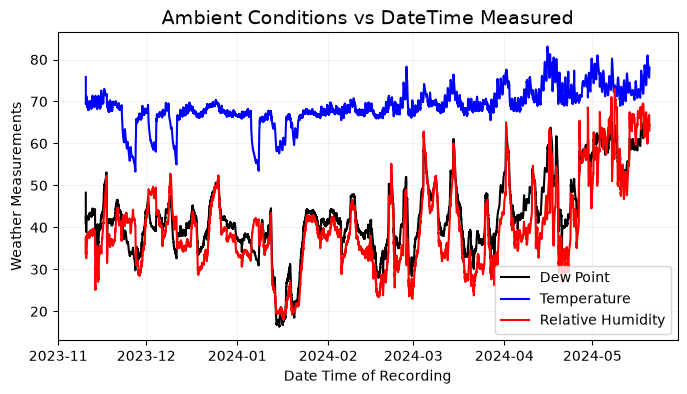

In [131]:
plt.figure(figsize=(8,4))
plt.plot(df["datetime"], df["dew_point_f"], label="Dew Point", color="black")
plt.plot(df["datetime"], df["temperature_f"], label="Temperature", color="blue")
plt.plot(df["datetime"], df["relative_humidity"], label="Relative Humidity", color="red")
plt.grid(color="gray", alpha=0.1)
plt.xlabel("Date Time of Recording")
plt.ylabel("Weather Measurements")
plt.title("Ambient Conditions vs DateTime Measured", fontsize=14)
plt.legend()
plt.show()

In [ ]:
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = XGBRegressor(random_state=42, n_estimators=100)
pipe = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", model),
])

if "datetime" in df.columns:
    df = df.set_index("datetime").sort_index()

df = df.sort_index()    
target = "temperature_f"

horizon = pd.Timedelta(minutes=10)

if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
    raise ValueError("Expected a DatetimeIndex with valid timestamps.")
if not df.index.is_unique:
    raise ValueError("Resolve duplicate timestamps before backtesting.")


X = df.apply(pd.to_numeric, errors="coerce")
current_temp = X[target]



0 days 00:10:00
Most common time steps:
datetime
0 days 00:10:00    27646
0 days 01:10:00        1
Name: count, dtype: int64


In [141]:
print(df.index.max())
print(df.index.min())
print(df.columns)
print(df.index)

2024-05-20 10:42:55
2023-11-10 09:52:55
Index(['temperature_f', 'relative_humidity', 'dew_point_f'], dtype='str')
DatetimeIndex(['2023-11-10 09:52:55', '2023-11-10 10:02:55',
               '2023-11-10 10:12:55', '2023-11-10 10:22:55',
               '2023-11-10 10:32:55', '2023-11-10 10:42:55',
               '2023-11-10 10:52:55', '2023-11-10 11:02:55',
               '2023-11-10 11:12:55', '2023-11-10 11:22:55',
               ...
               '2024-05-20 09:12:55', '2024-05-20 09:22:55',
               '2024-05-20 09:32:55', '2024-05-20 09:42:55',
               '2024-05-20 09:52:55', '2024-05-20 10:02:55',
               '2024-05-20 10:12:55', '2024-05-20 10:22:55',
               '2024-05-20 10:32:55', '2024-05-20 10:42:55'],
              dtype='datetime64[us]', name='datetime', length=27648, freq=None)


In [ ]:

# Build the model and pipeline
model = XGBRegressor(random_state=42, n_estimators=100)
pipe = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", model),
])

# Prepare the data without changing df_final
target = "battery_temperature(f)"
horizon = pd.Timedelta(minutes=5)

df = df_final.copy()
if "datetime(utc)" in df.columns:
    df = df.set_index("datetime(utc)")
df.index = pd.to_datetime(df.index, utc=True)

# Convert each column, then put the telemetry on a one-second grid.
df = (
    df.apply(pd.to_numeric, errors="coerce")
    .sort_index()
    .resample("1s", closed="right", label="right")
    .mean()
)

# Build X and y on the same time index.
X = df.drop(columns=[target])
y = df[target].shift(-300)  # 300 rows = 5 minutes on this grid

# Keep rows with a future label and a current temperature for the baseline.
current_temp = df[target]
valid = y.notna() & current_temp.notna()
X, y = X.loc[valid], y.loc[valid]

elapsed = X.index - df.index[0]


def backtest_block(start_minute, end_minute=None):
    start = pd.Timedelta(minutes=start_minute)

    # A training label is available five minutes after its feature row.
    train = elapsed + horizon < start
    test = elapsed >= start
    if end_minute is not None:
        test &= elapsed < pd.Timedelta(minutes=end_minute)

    if not train.any() or not test.any():
        raise ValueError(f"No usable training or test rows for minute {start_minute}.")

    fitted_pipe = clone(pipe)
    fitted_pipe.fit(X.loc[train], y.loc[train])
    predictions = fitted_pipe.predict(X.loc[test])

    return {
        "train_rows": int(train.sum()),
        "test_rows": int(test.sum()),
        "xgb_mae_f": mean_absolute_error(y.loc[test], predictions),
        "baseline_mae_f": mean_absolute_error(
            y.loc[test], current_temp.reindex(X.index[test])
        ),
    }


backtest = pd.DataFrame([
    {"forecast_times": "07:00–09:00", **backtest_block(7, 9)},
    {"forecast_times": "09:00–10:00", **backtest_block(9, 10)},
])
print(backtest.round(2).to_string(index=False))

# Run once after settling on the model settings.
print("Final holdout:", backtest_block(10))

forecast_times  train_rows  test_rows  xgb_mae_f  baseline_mae_f
   07:00–09:00         120        120       8.15            5.48
   09:00–10:00         240         60       6.42            5.57
Final holdout: {'train_rows': 300, 'test_rows': 63, 'xgb_mae_f': 7.433820555102144, 'baseline_mae_f': 5.968211428571421}
